# Séance 3 — Nettoyage et qualité des données

**Durée pratique : 3 h 30** &nbsp;·&nbsp; Ateliers 3.1 à 3.4

## Ce que vous saurez faire à la fin

- classer les valeurs manquantes et choisir un traitement adapté à chaque colonne ;
- détecter les valeurs aberrantes par écart interquartile et par score z, et arbitrer ;
- normaliser des chaînes de caractères pour éliminer les faux doublons ;
- écrire une fonction de nettoyage idempotente qui journalise ce qu'elle modifie.

> **Le principe directeur de la séance.** Une décision de nettoyage n'est jamais neutre :
> elle change les résultats en aval. Chaque choix doit donc être **explicite, justifié et
> tracé**. Un pipeline qui supprime 4 % des lignes sans le dire est un pipeline dangereux.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name in ('notebooks', 'Notebook') else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


In [2]:
def parse_price(series):
    """Convertit une colonne de prix mixte (nombre ou texte '123,45 EUR') en float."""
    text = series.astype(str).str.replace(' EUR', '', regex=False)
    return pd.to_numeric(text.str.replace(',', '.', regex=False).str.strip(),
                         errors='coerce')


sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
customers = pd.read_csv(RAW_DIR / 'clients.csv')
sales['prix_unitaire'] = parse_price(sales['prix_unitaire'])

print(sales.shape, customers.shape)

(17609, 11) (3060, 5)


---
## Atelier 3.1 — Cartographier les valeurs manquantes (60 min)

### Partie guidée

Avant de choisir un traitement, il faut savoir **pourquoi** la valeur est absente.
La typologie classique distingue trois cas :

| Type | Signification | Conséquence |
|---|---|---|
| MCAR | absence totalement aléatoire | supprimer ne biaise pas, on perd seulement de la puissance |
| MAR | absence expliquée par d'autres colonnes | imputation conditionnelle possible et souhaitable |
| MNAR | absence liée à la valeur elle-même | tout traitement biaise ; l'absence doit devenir une information |

On ne peut pas prouver le type à partir des seules données. On l'argumente à partir de la
connaissance du processus qui les a produites.

In [3]:
missing_summary = pd.DataFrame({
    'nb_manquants': sales.isna().sum(),
    'taux_pct': (sales.isna().mean() * 100).round(2),
})
missing_summary[missing_summary['nb_manquants'] > 0].sort_values('taux_pct', ascending=False)

,nb_manquants,taux_pct
remise_pct,1941,11.02
date_commande,350,1.99


In [4]:
# Les remises manquantes le sont-elles au hasard ? Comparons les lignes concernées
# au reste du jeu sur quelques variables.
has_no_discount = sales['remise_pct'].isna()

comparison = pd.DataFrame({
    'remise manquante': sales[has_no_discount][['quantite', 'prix_unitaire']].mean(),
    'remise renseignée': sales[~has_no_discount][['quantite', 'prix_unitaire']].mean(),
}).round(2)
print(comparison)
print()
print('Répartition des statuts, remise manquante :')
print(sales[has_no_discount]['statut'].value_counts(normalize=True).round(3))
print('Répartition des statuts, remise renseignée :')
print(sales[~has_no_discount]['statut'].value_counts(normalize=True).round(3))

               remise manquante  remise renseignée
quantite                   4.71               4.34
prix_unitaire            614.74             617.21

Répartition des statuts, remise manquante :
statut
livre       0.676
annule      0.173
retourne    0.150
Name: proportion, dtype: float64
Répartition des statuts, remise renseignée :
statut
livre       0.669
annule      0.168
retourne    0.164
Name: proportion, dtype: float64


**Lecture.** Si les deux profils sont semblables, l'hypothèse MCAR est plausible et une
imputation simple par zéro se défend (pas de remise saisie = pas de remise accordée).
S'ils diffèrent nettement, l'absence porte de l'information : créer un indicateur
`remise_absente` devient préférable à une imputation silencieuse.

### Partie autonome

In [5]:
# Q1. Même analyse pour la colonne 'age' de customers : les âges manquants se
#     concentrent-ils sur certains segments ou certaines villes ?

# TODO
age_missing = customers['age'].isna()
print('Âges manquants :', age_missing.sum(), f'({age_missing.mean():.1%})')
print()
print('Taux de manquants par segment :')
print(customers.groupby('segment')['age'].apply(lambda s: s.isna().mean()).round(3))
print()
# La ville est saisie avec des casses et des espaces variables : on la normalise
# (simplement, la fonction complète arrive à l'atelier 3.3) avant de grouper.
city_clean = customers['ville'].astype(str).str.strip().str.title()
print('Taux de manquants par ville (normalisée) :')
print(customers['age'].isna().groupby(city_clean).mean().round(3).sort_values(ascending=False))
print()
print('Âges renseignés :')
print(customers['age'].describe().round(1))
# Lecture : les taux par segment sont très proches (environ 6 %) et les écarts entre
# villes restent faibles et irréguliers ; rien ne suggère une absence liée à une autre
# colonne : l'hypothèse MCAR est plausible. En revanche, les âges renseignés contiennent
# des valeurs impossibles (négatives, 999) : ce sont des codes de saisie, à traiter
# comme des manquants avant toute imputation.

Âges manquants : 185 (6.0%)

Taux de manquants par segment :
segment
Association      0.065
Particulier      0.057
Professionnel    0.063
Name: age, dtype: float64

Taux de manquants par ville (normalisée) :
ville
Bordeaux      0.075
Marseille     0.075
Nantes        0.065
Lille         0.060
Lyon          0.058
Strasbourg    0.055
Paris         0.048
Toulouse      0.047
Name: age, dtype: float64

Âges renseignés :
count    2875.0
mean       46.5
std        80.9
min       -16.0
25%        31.0
50%        40.0
75%        49.0
max       999.0
Name: age, dtype: float64


In [6]:
# Q2. Rédiger une stratégie colonne par colonne, sous forme de dictionnaire.
#     Valeurs autorisées : 'drop_row', 'fill_zero', 'fill_median',
#     'fill_median_by_group', 'add_indicator', 'keep_as_is'.
#     La justification est OBLIGATOIRE : c'est elle qui sera évaluée, pas le choix lui-même.

missing_value_strategy = {
    'date_commande': ('drop_row',
                      'une commande sans date est inexploitable pour toute analyse temporelle'),
    'remise_pct':    ('fill_zero',
                      'profils (quantité, prix, statut) semblables avec ou sans remise : MCAR '
                      'plausible ; une remise non saisie correspond à une remise non accordée, '
                      'et 0 est déjà la valeur la plus fréquente (38 % des lignes)'),   # TODO
    'age':           ('fill_median_by_group',
                      'environ 6 % de manquants répartis uniformément (MCAR/MAR) ; la médiane par '
                      'segment respecte les écarts entre segments, et la médiane plutôt que la '
                      'moyenne car la colonne contient des valeurs aberrantes (999, âges négatifs) '
                      'qui tirent la moyenne vers le haut'),   # TODO
    'cout_achat':    ('fill_median_by_group',
                      'une seule valeur manquante sur 39 produits ; la supprimer ferait perdre '
                      'toutes les ventes du produit, la médiane de sa catégorie donne un coût '
                      'réaliste sans être influencée par les produits extrêmes'),   # TODO
}

for column, (action, rationale) in missing_value_strategy.items():
    print(f'{column:<16} {action:<24} {rationale}')

date_commande    drop_row                 une commande sans date est inexploitable pour toute analyse temporelle
remise_pct       fill_zero                profils (quantité, prix, statut) semblables avec ou sans remise : MCAR plausible ; une remise non saisie correspond à une remise non accordée, et 0 est déjà la valeur la plus fréquente (38 % des lignes)
age              fill_median_by_group     environ 6 % de manquants répartis uniformément (MCAR/MAR) ; la médiane par segment respecte les écarts entre segments, et la médiane plutôt que la moyenne car la colonne contient des valeurs aberrantes (999, âges négatifs) qui tirent la moyenne vers le haut
cout_achat       fill_median_by_group     une seule valeur manquante sur 39 produits ; la supprimer ferait perdre toutes les ventes du produit, la médiane de sa catégorie donne un coût réaliste sans être influencée par les produits extrêmes


---
## Atelier 3.2 — Valeurs aberrantes : deux méthodes, deux verdicts (55 min)

### Partie guidée

In [7]:
def iqr_bounds(series, factor=1.5):
    """Bornes de Tukey : robustes, car fondées sur des quantiles."""
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - factor * spread, q3 + factor * spread


def zscore_bounds(series, n_std=3):
    """Bornes par score z : sensibles, car moyenne et écart type sont eux-mêmes
    tirés vers le haut par les valeurs extrêmes."""
    mean, std = series.mean(), series.std()
    return mean - n_std * std, mean + n_std * std


quantity = sales['quantite']
for label, (lower, upper) in [('IQR    ', iqr_bounds(quantity)),
                              ('score z', zscore_bounds(quantity))]:
    n_flagged = ((quantity < lower) | (quantity > upper)).sum()
    print(f'{label} bornes [{lower:8.2f} ; {upper:8.2f}]  ->  {n_flagged:>4} valeurs signalées')

IQR     bornes [   -2.00 ;     6.00]  ->    74 valeurs signalées
score z bornes [ -119.00 ;   127.75]  ->    61 valeurs signalées


Les deux méthodes ne s'accordent pas, et l'écart est instructif. Le score z est calculé à
partir de la moyenne et de l'écart type, deux statistiques que les valeurs extrêmes
**déforment elles-mêmes**. Quelques quantités à 1 000 suffisent à gonfler l'écart type au
point que ces mêmes valeurs passent sous le seuil de détection. L'IQR, fondé sur des
quantiles, ne souffre pas de cet effet.

In [8]:
# Regarder les valeurs concernées avant de décider quoi que ce soit
print('Quantités les plus élevées :')
print(sales.nlargest(8, 'quantite')[['id_commande', 'quantite', 'prix_unitaire', 'statut']])
print()
print('Quantités négatives :', (sales['quantite'] < 0).sum())
print(sales[sales['quantite'] < 0][['id_commande', 'quantite', 'statut']].head())

Quantités les plus élevées :
      id_commande  quantite  prix_unitaire    statut
3498   CMD0000204      1199         542.83     livre
4204   CMD0000063      1163         949.23     livre
360    CMD0004120      1128         413.11     livre
10360  CMD0016201      1098         982.04  retourne
15880  CMD0003400      1092          66.77     livre
6745   CMD0002168      1081          90.34  retourne
12339  CMD0002491      1053         903.19  retourne
12341  CMD0006289      1002         614.04     livre

Quantités négatives : 30
     id_commande  quantite    statut
46    CMD0006153        -3     livre
757   CMD0017746        -4  retourne
1409  CMD0014959        -1     livre
1473  CMD0005010        -4    annule
1896  CMD0003955        -4     livre


**Deux problèmes de nature différente sont ici confondus.** Les quantités négatives sont
*impossibles* : c'est une erreur de saisie ou de signe, elle se corrige ou se supprime sans
état d'âme. Les quantités à 800 sont *improbables* mais pas impossibles : il peut s'agir de
commandes professionnelles légitimes. Les traiter de la même façon serait une faute
méthodologique.

### Partie autonome

In [9]:
# Q3. Écrire une fonction qui, pour une colonne donnée, renvoie un DataFrame comparant
#     les deux méthodes : nb détectés, part en %, valeur min et max des points signalés.

def compare_outlier_methods(df, column):
    ...  # TODO
    series = df[column].dropna()
    rows = {}
    for label, (lower, upper) in [('IQR', iqr_bounds(series)),
                                  ('score z', zscore_bounds(series))]:
        flagged = series[(series < lower) | (series > upper)]
        rows[label] = {
            'borne_basse': round(lower, 2),
            'borne_haute': round(upper, 2),
            'nb_detectes': len(flagged),
            'part_pct': round(len(flagged) / len(series) * 100, 2),
            'min_signale': flagged.min() if len(flagged) else np.nan,
            'max_signale': flagged.max() if len(flagged) else np.nan,
        }
    return pd.DataFrame(rows).T


# compare_outlier_methods(sales, 'quantite')
# compare_outlier_methods(sales, 'prix_unitaire')
print(compare_outlier_methods(sales, 'quantite'))
print()
print(compare_outlier_methods(sales, 'prix_unitaire'))

         borne_basse  borne_haute  nb_detectes  part_pct  min_signale  max_signale
IQR             -2.0         6.00         74.0      0.42         -4.0       1199.0
score z       -119.0       127.75         61.0      0.35        303.0       1199.0

         borne_basse  borne_haute  nb_detectes  part_pct  min_signale  max_signale
IQR          -693.53      1898.98          0.0       0.0          NaN          NaN
score z      -417.32      1651.20          0.0       0.0          NaN          NaN


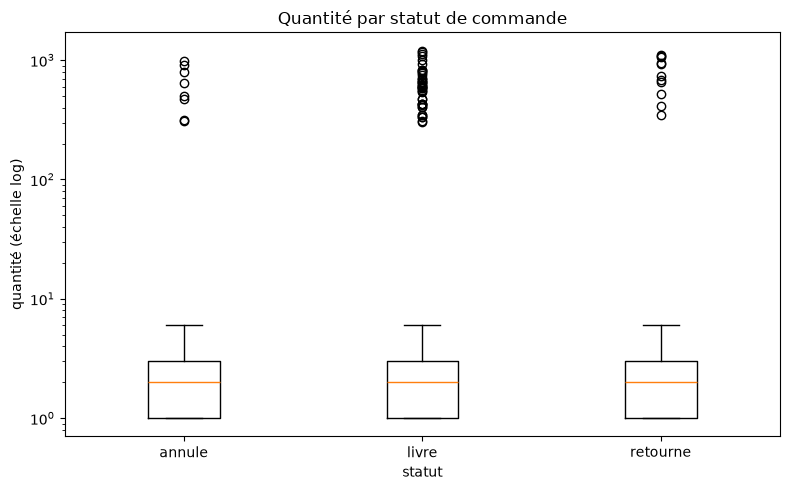

In [10]:
# Q4. Visualiser. Un boxplot par statut pour la quantité, en échelle logarithmique
#     sur l'axe des ordonnées (sans quoi les valeurs extrêmes écrasent tout le reste).

import matplotlib.pyplot as plt

# TODO
statut_clean = sales['statut'].astype(str).str.strip().str.lower()
positive = sales['quantite'] > 0          # l'échelle log n'accepte pas les valeurs <= 0
statuses = sorted(statut_clean[positive].unique())

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([sales.loc[positive & (statut_clean == s), 'quantite'] for s in statuses])
ax.set_xticks(range(1, len(statuses) + 1))
ax.set_xticklabels(statuses)
ax.set_yscale('log')
ax.set_xlabel('statut')
ax.set_ylabel('quantité (échelle log)')
ax.set_title('Quantité par statut de commande')
plt.tight_layout()
plt.show()

In [11]:
# Q5. Appliquer un traitement différencié et JOURNALISER ce qui est fait :
#       - quantités négatives : à décider et justifier ;
#       - quantités au-delà de la borne haute IQR : à décider et justifier.
#     La fonction renvoie (df_traité, log) où log est un dict des comptes.

def handle_quantity_outliers(df):
    df = df.copy()
    log = {}
    # TODO
    # Quantités négatives : IMPOSSIBLES (erreur de signe ou de saisie). On ne peut pas
    # savoir si -3 voulait dire 3 ou si la ligne est fausse : on supprime, peu de lignes.
    negative = df['quantite'] < 0
    log['quantites_negatives_supprimees'] = int(negative.sum())
    df = df[~negative]

    # Quantités au-delà de la borne haute IQR : IMPROBABLES mais pas impossibles
    # (commandes professionnelles). On les conserve, mais on les signale par un
    # indicateur pour pouvoir les exclure ou les étudier à part en aval.
    _, upper = iqr_bounds(df['quantite'])
    df['quantite_extreme'] = df['quantite'] > upper
    log['borne_haute_iqr'] = float(upper)
    log['quantites_extremes_signalees'] = int(df['quantite_extreme'].sum())
    log['lignes_restantes'] = len(df)
    return df, log


# sales_fixed, quantity_log = handle_quantity_outliers(sales)
# print(quantity_log)
sales_fixed, quantity_log = handle_quantity_outliers(sales)
print(quantity_log)

{'quantites_negatives_supprimees': 30, 'borne_haute_iqr': 6.0, 'quantites_extremes_signalees': 61, 'lignes_restantes': 17579}


---
## Atelier 3.3 — Doublons et incohérences textuelles (45 min)

### Partie guidée

In [12]:
print('Doublons stricts (toutes colonnes identiques) :', sales.duplicated().sum())
print('Doublons sur id_commande seul                 :', sales.duplicated('id_commande').sum())

Doublons stricts (toutes colonnes identiques) : 240
Doublons sur id_commande seul                 : 240


Les deux comptes diffèrent : certaines lignes partagent un identifiant de commande sans
être identiques. Avant de supprimer, il faut regarder ce qui les distingue.

In [13]:
repeated_ids = sales[sales.duplicated('id_commande', keep=False)]['id_commande'].unique()[:2]
sales[sales['id_commande'].isin(repeated_ids)].sort_values('id_commande')

,id_commande,date_commande,id_client,id_produit,id_magasin,quantite,prix_unitaire,remise_pct,canal,statut,ville_livraison
13,CMD0000105,2023/07/29 19:47,C01517,P0014,M99,2,1053.99,NaN,web,livre,Lyon
13443,CMD0000105,2023/07/29 19:47,C01517,P0014,M99,2,1053.99,NaN,web,livre,Lyon
18,CMD0000173,24-05-2023,C02747,P0002,M02,2,538.60,15.0,BOUTIQUE,annule,Marseille
2557,CMD0000173,24-05-2023,C02747,P0002,M02,2,538.60,15.0,BOUTIQUE,annule,Marseille


In [14]:
# Faux doublons textuels : la même ville écrite de plusieurs façons
print(sales['ville_livraison'].value_counts().head(12))

ville_livraison
Toulouse      1560
Lyon          1523
Paris         1521
Bordeaux      1510
Lille         1475
Marseille     1473
Nantes        1471
Strasbourg    1379
STRASBOURG     295
lyon           278
LYON           275
paris          275
Name: count, dtype: int64


In [15]:
def normalize_text(series):
    """Casse, espaces et accents : trois sources de faux niveaux."""
    text = series.astype(str).str.strip().str.lower()
    text = text.str.normalize('NFKD').str.encode('ascii', 'ignore').str.decode('utf-8')
    return text.str.replace(r'\s+', ' ', regex=True)


print('Modalités avant normalisation :', sales['ville_livraison'].nunique())
print('Modalités après normalisation :', normalize_text(sales['ville_livraison']).nunique())

Modalités avant normalisation : 33
Modalités après normalisation : 9


### Le piège : ne jamais normaliser les colonnes identifiantes

La tentation est grande d'écrire `for column in df.select_dtypes('object'): df[column] = normalize_text(df[column])`
et d'en finir. **C'est une erreur qui casse silencieusement tout le pipeline.** Les colonnes
`id_client`, `id_produit`, `id_magasin` sont du texte pour pandas, mais ce sont des **clés**.
Les passer en minuscules transforme `P0027` en `p0027`, et la jointure de la séance 6 ne
trouvera plus aucune correspondance : vous obtiendrez un jeu entièrement vide, sans la
moindre erreur levée.

Déclarez donc explicitement les colonnes à normaliser, plutôt que de les déduire du type.

In [16]:
TEXT_COLUMNS = ['canal', 'statut', 'ville_livraison']          # descriptives uniquement
KEY_COLUMNS = ['id_commande', 'id_client', 'id_produit', 'id_magasin']  # à préserver

trial = sales.copy()
for column in TEXT_COLUMNS:
    trial[column] = normalize_text(trial[column])

print('Clés intactes            :', trial['id_produit'].str.isupper().all())
print('Descriptives normalisées :', trial['canal'].nunique(), 'modalités')

Clés intactes            : True
Descriptives normalisées : 3 modalités


### Partie autonome

In [17]:
# Q6. Normaliser toutes les colonnes de TEXT_COLUMNS, puis recompter les doublons stricts.
#     Le compte augmente-t-il ? Expliquez pourquoi dans un commentaire.

# TODO
normalized = sales.copy()
for column in TEXT_COLUMNS:
    normalized[column] = normalize_text(normalized[column])

print('Doublons stricts avant normalisation :', sales.duplicated().sum())
print('Doublons stricts après normalisation :', normalized.duplicated().sum())
# Le compte ne peut que rester stable ou augmenter : deux lignes qui ne différaient
# que par l'écriture d'un texte ('Paris' / ' PARIS ') deviennent identiques une fois
# normalisées. Ici il reste stable : les doublons stricts du fichier sont des copies
# exactes de lignes (même graphie), et les variantes d'écriture touchent des commandes
# différentes. C'est pour cette raison que clean_sales normalise AVANT de dédoublonner.

Doublons stricts avant normalisation : 240
Doublons stricts après normalisation : 240


In [18]:
# Q7. Dans customers, identifier les doublons MÉTIER : même ville, même segment,
#     même date d'inscription et même âge, mais identifiant différent.
#     Combien de couples trouvez-vous ? Que proposez-vous d'en faire ?

# TODO
customers_check = customers.copy()
customers_check['ville_norm'] = normalize_text(customers_check['ville'])
business_key = ['ville_norm', 'segment', 'date_inscription', 'age']

business_duplicates = (customers_check[customers_check.duplicated(business_key, keep=False)]
                       .sort_values(business_key))
pairs = business_duplicates.groupby(business_key, dropna=False)['id_client'].nunique()
print('Couples de doublons métier :', (pairs > 1).sum())
print(business_duplicates[['id_client'] + business_key].head(10))
# Proposition : les identifiants en double ont un format différent (numérique 99xxxx
# au lieu de Cxxxxx), signe d'un second import du même client. On ne supprime pas
# directement : des ventes peuvent référencer l'un ou l'autre identifiant. On construit
# une table de correspondance id_doublon -> id_canonique (format Cxxxxx), on remappe
# id_client dans les ventes, puis on supprime le doublon dans customers.

Couples de doublons métier : 60
     id_client ville_norm      segment date_inscription   age
63      C00064   bordeaux  Particulier       2019-11-28  23.0
3041    990041   bordeaux  Particulier       2019-11-28  23.0
1001    C01002   bordeaux  Particulier       2022-05-30  41.0
3059    990059   bordeaux  Particulier       2022-05-30  41.0
1241    C01242   bordeaux  Particulier       2024-01-13  44.0
3029    990029   bordeaux  Particulier       2024-01-13  44.0
781     C00782   bordeaux  Particulier       2024-02-13  24.0
3035    990035   bordeaux  Particulier       2024-02-13  24.0
727     C00728   bordeaux  Particulier       2024-03-16  51.0
3043    990043   bordeaux  Particulier       2024-03-16  51.0


---
## Atelier 3.4 — Un module de nettoyage idempotent (50 min)

**Idempotent** signifie que réappliquer la fonction à son propre résultat ne change plus rien.
C'est une propriété essentielle : un pipeline relancé deux fois par erreur ne doit pas
produire un jeu de données différent.

In [19]:
def clean_sales(df, drop_negative_quantities=True, max_quantity=None, verbose=True):
    """Nettoie le jeu de ventes et renvoie (df_propre, log).

    Étapes attendues, dans cet ordre :
      1. copier le DataFrame reçu (ne jamais modifier l'entrée) ;
      2. convertir prix_unitaire en numérique ;
      3. normaliser les colonnes texte DESCRIPTIVES (jamais les identifiants) ;
      4. supprimer les doublons stricts ;
      5. convertir date_commande en datetime et supprimer les lignes sans date ;
      6. appliquer la stratégie retenue pour remise_pct ;
      7. traiter les quantités selon les paramètres ;
      8. calculer la colonne montant.

    Le log recense, pour chaque étape, le nombre de lignes ou de valeurs touchées.
    """
    log = {'lignes_initiales': len(df)}
    df = df.copy()
    # TODO
    df['prix_unitaire'] = parse_price(df['prix_unitaire'])

    for column in TEXT_COLUMNS:
        df[column] = normalize_text(df[column])

    n_before = len(df)
    df = df.drop_duplicates()
    log['doublons_stricts_supprimes'] = n_before - len(df)

    df['date_commande'] = pd.to_datetime(df['date_commande'], format='mixed', dayfirst=True, errors='coerce')
    n_before = len(df)
    df = df[df['date_commande'].notna()]
    log['lignes_sans_date_supprimees'] = n_before - len(df)

    n_filled = df['remise_pct'].isna().sum()
    df['remise_pct'] = df['remise_pct'].fillna(0)
    log['remise_pct_imputee_zero'] = int(n_filled)

    if drop_negative_quantities:
        n_before = len(df)
        df = df[df['quantite'] >= 0]
        log['quantites_negatives_supprimees'] = n_before - len(df)
    else:
        log['quantites_negatives_supprimees'] = 0

    if max_quantity is not None:
        n_before = len(df)
        df = df[df['quantite'] <= max_quantity]
        log['quantites_hors_plafond_supprimees'] = n_before - len(df)
    else:
        log['quantites_hors_plafond_supprimees'] = 0

    df['montant'] = df['quantite'] * df['prix_unitaire'] * (1 - df['remise_pct'] / 100)

    log['lignes_finales'] = len(df)
    if verbose:
        for key, value in log.items():
            print(f'  {key:<28} {value}')
    return df, log


clean_sales_df, cleaning_log = clean_sales(pd.read_csv(RAW_DIR / 'ventes_brutes.csv'))

  lignes_initiales             17609
  doublons_stricts_supprimes   240
  lignes_sans_date_supprimees  347
  remise_pct_imputee_zero      1874
  quantites_negatives_supprimees 30
  quantites_hors_plafond_supprimees 0
  lignes_finales               16992


In [20]:
# Q8. Vérifier l'idempotence : un second passage ne doit rien changer.

second_pass, _ = clean_sales(clean_sales_df, verbose=False)

assert len(second_pass) == len(clean_sales_df), "la fonction n'est pas idempotente"
assert second_pass.equals(clean_sales_df), 'le second passage modifie encore des valeurs'
print('OK — fonction idempotente')

OK — fonction idempotente


In [21]:
# Export du résultat et du journal, pour la séance 4.

import json

save_dataset(clean_sales_df, 'ventes_nettoyees')

with open(PROCESSED_DIR / 'journal_nettoyage.json', 'w', encoding='utf-8') as file:
    json.dump(cleaning_log, file, indent=2, ensure_ascii=False, default=str)

kept_ratio = len(clean_sales_df) / cleaning_log['lignes_initiales']
print('Lignes conservées :', len(clean_sales_df), f'({kept_ratio:.1%} du brut)')

écrit : ventes_nettoyees.parquet (16992, 12)
Lignes conservées : 16992 (96.5% du brut)


---
## Livrable de la séance

- `src/cleaning.py` contenant `clean_sales`, importable et testée ;
- `data/processed/ventes_nettoyees.parquet` ;
- `data/processed/journal_nettoyage.json` ;
- le tableau des stratégies (question 2) avec sa justification écrite, colonne par colonne.

**Ce tableau sera repris tel quel dans votre note méthodologique de projet et vous sera
demandé en soutenance.** Attendez-vous à la question : *pourquoi la médiane plutôt que la
moyenne sur cette colonne ?*